# 05 — Entraînement baseline vision (KneeNet)

Lance `src/train/train.py` avec `configs/baseline.yaml` et affiche les courbes.

- Entrée : 3 plans (sag/cor/ax, fluid prioritaire) × 24 slices × 224², déjà bande 20–80 % dans les NPZ
- Modèle : vrai 2.5D RGB — chaque coupe → ConvNeXt-tiny ImageNet → attention **12 têtes** (une par cible) sur les 72 tokens
- Loss : BCE masquée (-1 = ignoré). Train (avec aug) vs val (sans aug) dans `history.json`
- Métrique : macro-AUC val (pseudo-labels) vs macro-AUC gold (58, jamais pour le checkpoint)

Sur RTX 3070 (8 Go) : batch 4 + `encode_chunk` 16 + gradient checkpointing. Plus lent que l'ancien 24-canaux (~15–30 min/epoch).

Les colonnes `val_loss` et `gold_macro_auc` n'existent qu'après une run **post** ce changement. Relancer l'entraînement pour les graphes complets.

In [1]:
# L'entrainement se lance en terminal (plus robuste que dans le notebook) :
#   python -X utf8 -m src.train.train --config configs/baseline.yaml
# Cette cellule attend la fin et affiche l'historique.
import json, time
from pathlib import Path

run_dir = Path.cwd().parent / 'checkpoints' / 'baseline_v8_25d_attn'
hist_path = run_dir / 'history.json'
print('en attente de', hist_path, '...')
while not hist_path.exists():
    time.sleep(30)
print('termine')

en attente de c:\Users\sulta\Documents\RSNA-comp\checkpoints\baseline_v7_new_labels\history.json ...
termine


,epoch,loss,val_loss,val_macro_auc,gold_macro_auc
0,1,0.5331,0.5021,0.6735,0.6217
1,2,0.4973,0.4724,0.7089,0.6587
2,3,0.4781,0.4446,0.7409,0.7223
3,4,0.4529,0.4298,0.7640,0.7678
4,5,0.4325,0.4183,0.7802,0.7894
5,6,0.4108,0.4123,0.7892,0.7878
6,7,0.3920,0.4086,0.8005,0.8174
7,8,0.3641,0.4071,0.8031,0.8159
8,9,0.3463,0.4139,0.8056,0.8149
9,10,0.3213,0.4209,0.8071,0.8192


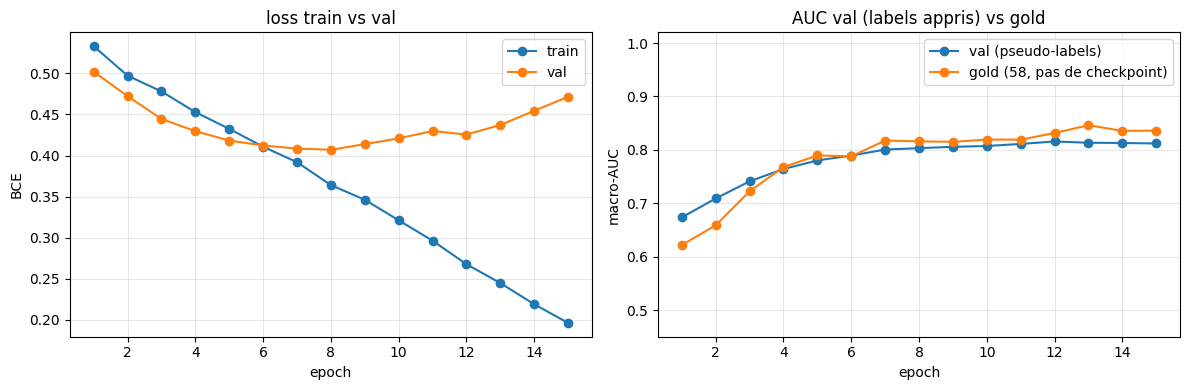

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

hist = pd.DataFrame(json.loads(hist_path.read_text()))
show = [c for c in ('epoch', 'loss', 'val_loss', 'val_macro_auc', 'gold_macro_auc') if c in hist.columns]
display(hist[show].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist.epoch, hist.loss, marker='o', label='train')
if 'val_loss' in hist.columns:
    axes[0].plot(hist.epoch, hist.val_loss, marker='o', label='val')
else:
    print('val_loss absent : relancer train.py pour la comparer a la train loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('BCE')
axes[0].set_title('loss train vs val')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hist.epoch, hist.val_macro_auc, marker='o', label='val (pseudo-labels)')
if 'gold_macro_auc' in hist.columns:
    axes[1].plot(hist.epoch, hist.gold_macro_auc, marker='o', label='gold (58, pas de checkpoint)')
else:
    print('gold_macro_auc absent : relancer train.py pour la courbe gold vs val')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('macro-AUC')
axes[1].set_title('AUC val (labels appris) vs gold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(0.45, 1.02)

plt.tight_layout()
plt.show()

In [3]:
# Sanity check gold du best.pt (58 etudes, jamais pour le checkpoint)
gold_path = run_dir / 'gold_sanity.json'
if gold_path.exists():
    gold = json.loads(gold_path.read_text())
    ep = gold.get('epoch', '?')
    print(f"macro-AUC gold (best.pt, epoch {ep}) :", round(gold['macro_auc'], 4))
    display(pd.Series(gold['per_target']).sort_values(ascending=False).round(3))
    if 'gold_macro_auc' in hist.columns:
        last = hist.iloc[-1]
        print('derniere epoch — val AUC :', round(last.val_macro_auc, 4),
              '| gold AUC :', round(last.gold_macro_auc, 4),
              '| ecart :', round(last.val_macro_auc - last.gold_macro_auc, 4))
else:
    print('pas de gold_sanity.json')

macro-AUC gold (best.pt, epoch 12) : 0.8315


Baker's             0.934
MCL                 0.932
Medial OA           0.887
Fracture            0.885
ACL                 0.876
Effusion            0.871
Contusion           0.818
Medial Meniscus     0.816
PF OA               0.797
Lateral OA          0.758
Synovitis           0.701
Lateral Meniscus    0.701
dtype: float64

derniere epoch — val AUC : 0.8119 | gold AUC : 0.8359 | ecart : -0.024
